In [ ]:
print("Simulación de señales y Transformada de Fourier")
print("Mi primera prueba en Python funciona")


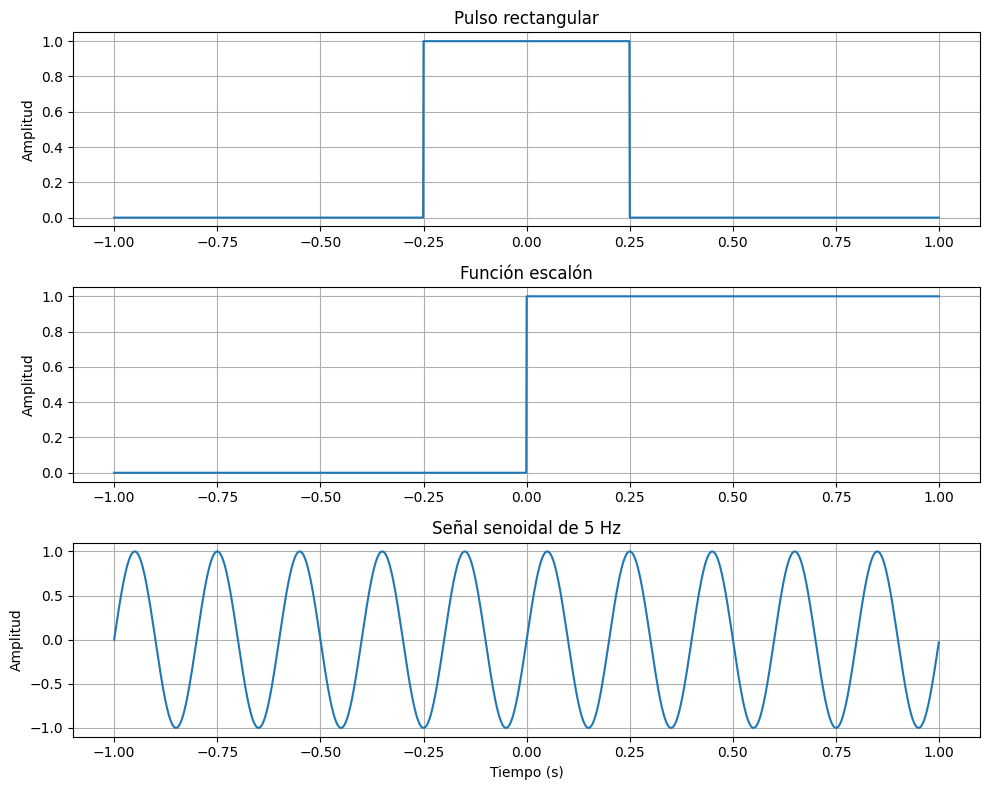

In [1]:

import numpy as np
import matplotlib.pyplot as plt

# Configuración del tiempo
fs = 1000  # Frecuencia de muestreo en Hz
t = np.arange(-1, 1, 1/fs)

# 1. Pulso rectangular
pulso = np.where((t >= -0.25) & (t <= 0.25), 1, 0)

# 2. Función escalón
escalon = np.where(t >= 0, 1, 0)

# 3. Señal senoidal de 5 Hz
f0 = 5
senoidal = np.sin(2 * np.pi * f0 * t)

# Gráficas en el dominio del tiempo
fig, axes = plt.subplots(3, 1, figsize=(10, 8))

axes[0].plot(t, pulso)
axes[0].set_title("Pulso rectangular")
axes[0].set_ylabel("Amplitud")
axes[0].grid()

axes[1].plot(t, escalon)
axes[1].set_title("Función escalón")
axes[1].set_ylabel("Amplitud")
axes[1].grid()

axes[2].plot(t, senoidal)
axes[2].set_title("Señal senoidal de 5 Hz")
axes[2].set_xlabel("Tiempo (s)")
axes[2].set_ylabel("Amplitud")
axes[2].grid()

plt.tight_layout()
plt.show()


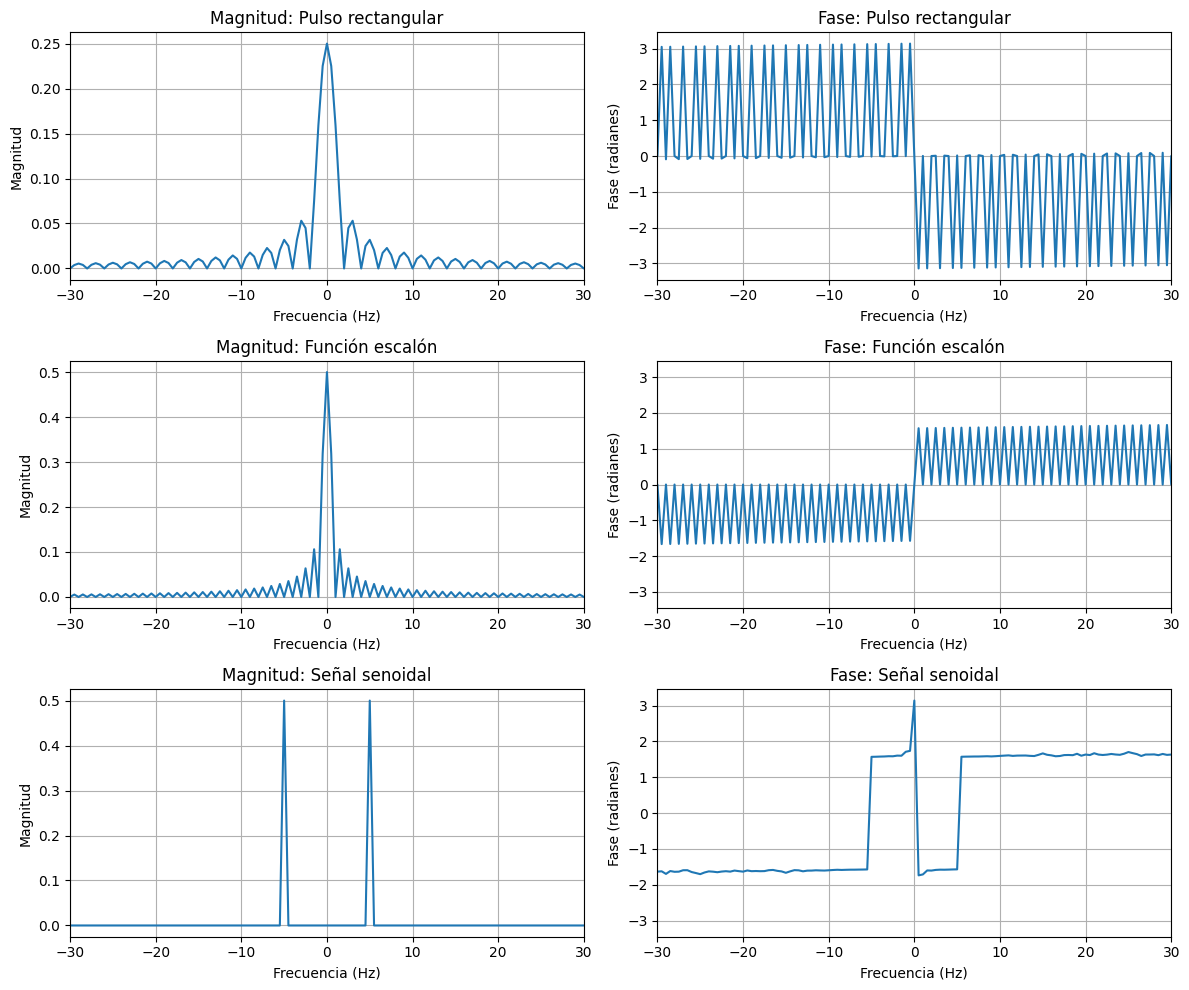

In [2]:

# Transformada de Fourier usando FFT

# Lista de señales
senales = {
    "Pulso rectangular": pulso,
    "Función escalón": escalon,
    "Señal senoidal": senoidal
}

# Eje de frecuencias
frecuencias = np.fft.fftfreq(len(t), d=1/fs)

# Calcular y graficar magnitud y fase
fig, axes = plt.subplots(3, 2, figsize=(12, 10))

for i, (nombre, señal) in enumerate(senales.items()):

    # Transformada de Fourier
    transformada = np.fft.fft(señal)

    # Centrar las frecuencias en cero
    transformada_centrada = np.fft.fftshift(transformada)
    frecuencias_centradas = np.fft.fftshift(frecuencias)

    # Magnitud normalizada
    magnitud = np.abs(transformada_centrada) / len(señal)

    # Fase
    fase = np.angle(transformada_centrada)

    # Graficar magnitud
    axes[i, 0].plot(frecuencias_centradas, magnitud)
    axes[i, 0].set_title(f"Magnitud: {nombre}")
    axes[i, 0].set_xlabel("Frecuencia (Hz)")
    axes[i, 0].set_ylabel("Magnitud")
    axes[i, 0].set_xlim(-30, 30)
    axes[i, 0].grid()

    # Graficar fase
    axes[i, 1].plot(frecuencias_centradas, fase)
    axes[i, 1].set_title(f"Fase: {nombre}")
    axes[i, 1].set_xlabel("Frecuencia (Hz)")
    axes[i, 1].set_ylabel("Fase (radianes)")
    axes[i, 1].set_xlim(-30, 30)
    axes[i, 1].grid()

plt.tight_layout()
plt.show()


1. PROPIEDAD DE LINEALIDAD
Error máximo: 4.508208201844495e-13
Se cumple si el error es cercano a cero.



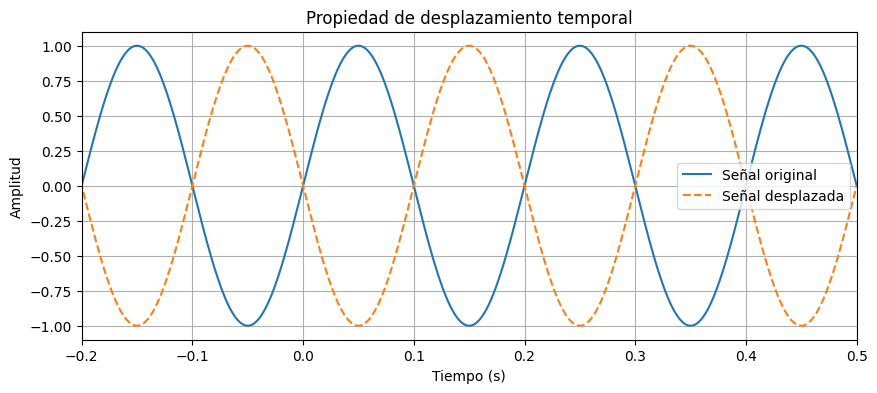

2. DESPLAZAMIENTO TEMPORAL
La señal cambia de posición en el tiempo.
En el dominio de frecuencia, el desplazamiento
modifica la fase, pero no la magnitud.



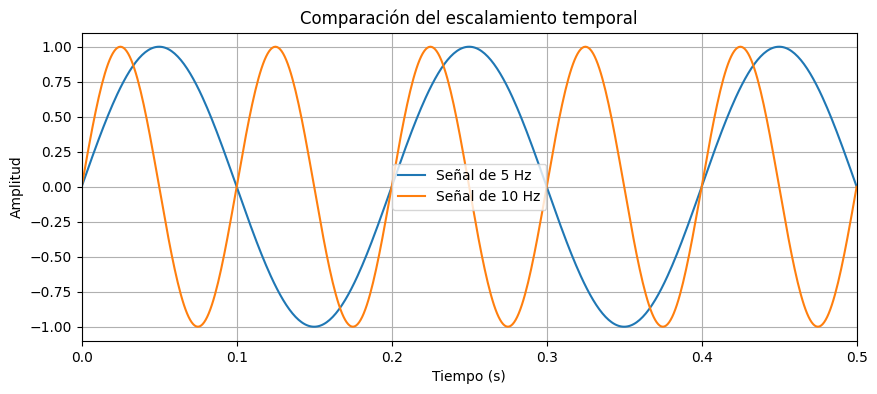

3. ESCALAMIENTO
Al comprimir una señal en el tiempo,
su contenido se desplaza hacia frecuencias mayores.


In [3]:

# PROPIEDADES DE LA TRANSFORMADA DE FOURIER

# 1. Linealidad
# La transformada de a*x + b*y debe ser a*X + b*Y

a = 2
b = 3

X = np.fft.fft(pulso)
Y = np.fft.fft(senoidal)

combinacion = a * pulso + b * senoidal
transformada_combinacion = np.fft.fft(combinacion)

error_linealidad = np.max(
    np.abs(transformada_combinacion - (a * X + b * Y))
)

print("1. PROPIEDAD DE LINEALIDAD")
print("Error máximo:", error_linealidad)
print("Se cumple si el error es cercano a cero.\n")


# 2. Desplazamiento en el tiempo
# Desplazamos la señal senoidal 0.1 segundos

desplazamiento = 0.1
senoidal_desplazada = np.sin(
    2 * np.pi * f0 * (t - desplazamiento)
)

X_original = np.fft.fft(senoidal)
X_desplazada = np.fft.fft(senoidal_desplazada)

plt.figure(figsize=(10, 4))
plt.plot(t, senoidal, label="Señal original")
plt.plot(t, senoidal_desplazada, "--",
         label="Señal desplazada")
plt.xlim(-0.2, 0.5)
plt.title("Propiedad de desplazamiento temporal")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.legend()
plt.grid()
plt.show()

print("2. DESPLAZAMIENTO TEMPORAL")
print("La señal cambia de posición en el tiempo.")
print("En el dominio de frecuencia, el desplazamiento")
print("modifica la fase, pero no la magnitud.\n")


# 3. Escalamiento en el tiempo
# Comparamos una señal de 5 Hz con otra de 10 Hz

senoidal_rapida = np.sin(2 * np.pi * 10 * t)

plt.figure(figsize=(10, 4))
plt.plot(t, senoidal, label="Señal de 5 Hz")
plt.plot(t, senoidal_rapida, label="Señal de 10 Hz")
plt.xlim(0, 0.5)
plt.title("Comparación del escalamiento temporal")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.legend()
plt.grid()
plt.show()

print("3. ESCALAMIENTO")
print("Al comprimir una señal en el tiempo,")
print("su contenido se desplaza hacia frecuencias mayores.")
